# ADV ATLAS Project

## Phase 0 

## Phase 1 - Coincidence, Hazards and Safety Model

### Task 1.1

Parameters loaded from outputs/phase1/coincidence_window.json

Rule: distance <= 13.6 km (+4.3 km altimeter) + 43.2 km per hour of lag, capped at 300 km

Allowed distance [km] (SAR) vs |lag|:
  |lag| [h]       0   0.5     1   1.5     2     3     4     5     6
  strict         14    35    57    78     —     —     —     —     —
  baseline       14    35    57    78   100   143     —     —     —
  relaxed        14    35    57    78   100   143   186   230   273


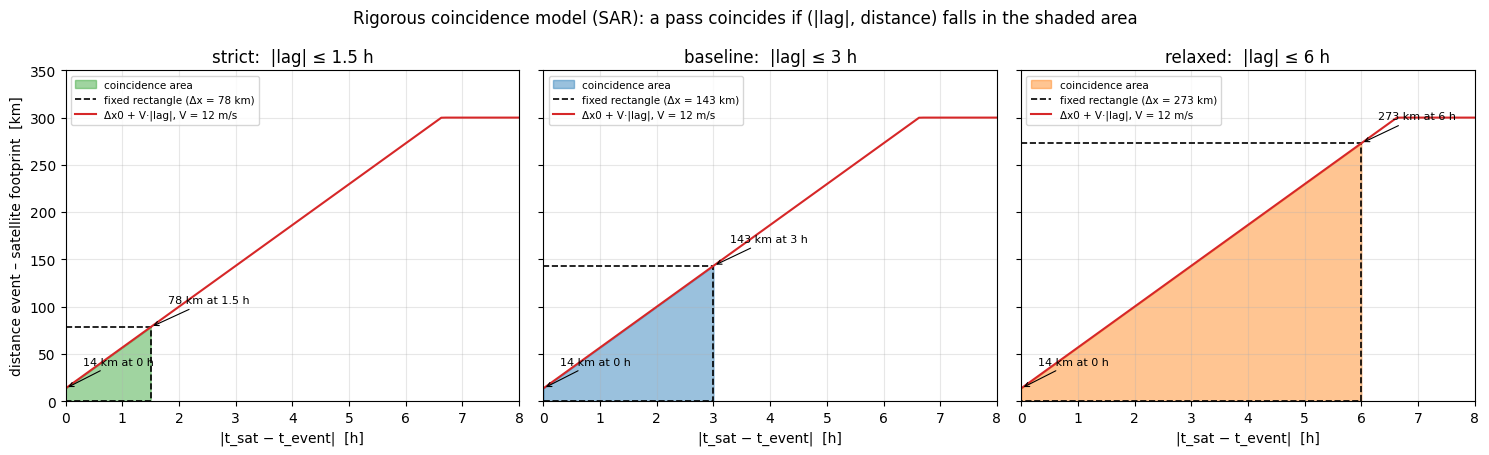

COINCIDENCE [baseline, sar]: pass 1.0 h before the event at 44 km (allowed: |lag| <= 3 h and distance <= 57 km at this lag)
no coincidence [baseline, sar]: pass 1.0 h before the event at 111 km (allowed: |lag| <= 3 h and distance <= 57 km at this lag)
COINCIDENCE [baseline, sar]: pass 2.5 h before the event at 111 km (allowed: |lag| <= 3 h and distance <= 122 km at this lag)


In [ ]:
# =============================================================================
# TASK 1.1 - Coincidence model, RIGOROUS version (lag-dependent distance)
# Standalone: reads outputs/phase1/coincidence_window.json (CELL 1) if present,
# otherwise uses the hard-coded defaults below.
#
# Rule:  a satellite pass and a hazard event (= ship transit point) COINCIDE if
#        |t_sat - t_event| <= Δt_tier
#        and distance(event, footprint) <= Δx(|lag|) = min(Δx0 + V·|lag|, L_cap)
# -> the closer in time, the closer in space the pass must be.
# =============================================================================
import json, os, math
from datetime import datetime, timezone
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------ parameters ----
DEFAULTS = {"grid_half_diag_km": 13.62, "altimeter_footprint_radius_km": 4.32,
            "propagation_speed_used_ms": 12.0, "hs_decorr_length_km": 300.0}
DEFAULT_TIERS = {"strict": 1.5, "baseline": 3.0, "relaxed": 6.0}
path = "outputs/phase1/coincidence_window.json"
if os.path.exists(path):
    with open(path) as f:
        cw = json.load(f)
    sc = {**DEFAULTS, **cw["scales"]}
    TIERS = {k: v["dt_hours"] for k, v in cw["windows"].items()}
    print(f"Parameters loaded from {path}")
else:
    sc, TIERS = DEFAULTS, DEFAULT_TIERS
    print("CELL 1 JSON not found -> using hard-coded defaults")

V_KMH = sc["propagation_speed_used_ms"] * 3.6
L_CAP_KM = sc["hs_decorr_length_km"]
DX0_KM = {"sar": sc["grid_half_diag_km"],
          "altimeter": sc["grid_half_diag_km"] + sc["altimeter_footprint_radius_km"]}

# ---------------------------------------------------------- the model ------
def allowed_distance_km(lag_h, sensor="sar"):
    """Maximum event–satellite distance [km] accepted at time lag |lag_h|."""
    return min(DX0_KM[sensor] + V_KMH * abs(lag_h), L_CAP_KM)

def _haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = math.radians(lat1), math.radians(lat2)
    a = math.sin((p2 - p1) / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(math.radians(lon2 - lon1) / 2) ** 2
    return 2 * 6371.0 * math.asin(math.sqrt(a))

def _utc(t):
    t = datetime.fromisoformat(t.replace("Z", "+00:00")) if isinstance(t, str) else t
    return t if t.tzinfo else t.replace(tzinfo=timezone.utc)

def coincidence(event_lat, event_lon, event_time, sat_lat, sat_lon, sat_time,
                sensor="sar", tier="baseline", distance_km=None):
    """Yes/no coincidence verdict between ONE hazard event and ONE satellite sample.
    sat_lat/sat_lon: nearest footprint point to the event (or pass distance_km directly,
    e.g. the event–polygon distance for a SAR footprint)."""
    lag_h = (_utc(sat_time) - _utc(event_time)).total_seconds() / 3600.0
    dist = distance_km if distance_km is not None else _haversine_km(event_lat, event_lon, sat_lat, sat_lon)
    dt_max = TIERS[tier]
    dx_max = allowed_distance_km(lag_h, sensor)
    ok = abs(lag_h) <= dt_max and dist <= dx_max
    when = "before" if lag_h < 0 else "after"
    msg = (f"{'COINCIDENCE' if ok else 'no coincidence'} [{tier}, {sensor}]: pass {abs(lag_h):.1f} h {when} "
           f"the event at {dist:.0f} km (allowed: |lag| <= {dt_max:g} h and distance <= {dx_max:.0f} km at this lag)")
    return {"coincident": ok, "lag_h": round(lag_h, 2), "distance_km": round(dist, 1),
            "max_lag_h": dt_max, "max_distance_km": round(dx_max, 1), "message": msg}

# ------------------------------------------------- the rule in numbers -----
print(f"\nRule: distance <= {DX0_KM['sar']:.1f} km (+{DX0_KM['altimeter'] - DX0_KM['sar']:.1f} km altimeter)"
      f" + {V_KMH:.1f} km per hour of lag, capped at {L_CAP_KM:.0f} km\n")
lags_tab = [0, 0.5, 1, 1.5, 2, 3, 4, 5, 6]
print("Allowed distance [km] (SAR) vs |lag|:")
print("  |lag| [h]  " + "".join(f"{l:>6g}" for l in lags_tab))
for tier, dt_t in TIERS.items():
    row = "".join(f"{allowed_distance_km(l):6.0f}" if l <= dt_t else f"{'—':>6s}" for l in lags_tab)
    print(f"  {tier:10s} " + row)

# --------------------------------------------------------------- figure ----
colors = {"strict": "tab:green", "baseline": "tab:blue", "relaxed": "tab:orange"}
sensor = "sar"
fig, axs = plt.subplots(1, len(TIERS), figsize=(15, 4.6), sharey=True)
for ax, (tier, dt_t) in zip(axs, TIERS.items()):
    l = np.linspace(0, dt_t, 200)
    dx_l = np.minimum(DX0_KM[sensor] + V_KMH * l, L_CAP_KM)
    ax.fill_between(l, 0, dx_l, color=colors.get(tier, "grey"), alpha=0.45, label="coincidence area")
    ax.plot([0, dt_t, dt_t, 0], [dx_l[-1]] * 2 + [0, 0], ls="--", color="k", lw=1.2,
            label=f"fixed rectangle (Δx = {dx_l[-1]:.0f} km)")
    ll = np.linspace(0, 8, 100)
    ax.plot(ll, np.minimum(DX0_KM[sensor] + V_KMH * ll, L_CAP_KM), color="tab:red", lw=1.5,
            label=f"Δx0 + V·|lag|, V = {V_KMH / 3.6:.0f} m/s")
    ax.annotate(f"{dx_l[0]:.0f} km at 0 h", (0, dx_l[0]), xytext=(0.3, dx_l[0] + 25), fontsize=8,
                arrowprops=dict(arrowstyle="->", lw=0.8))
    ax.annotate(f"{dx_l[-1]:.0f} km at {dt_t:g} h", (dt_t, dx_l[-1]), xytext=(dt_t + 0.3, dx_l[-1] + 25),
                fontsize=8, arrowprops=dict(arrowstyle="->", lw=0.8))
    ax.set(title=f"{tier}:  |lag| ≤ {dt_t:g} h", xlabel="|t_sat − t_event|  [h]", xlim=(0, 8), ylim=(0, 350))
    ax.grid(alpha=0.3); ax.legend(fontsize=7.5, loc="upper left")
axs[0].set_ylabel("distance event – satellite footprint  [km]")
fig.suptitle("Rigorous coincidence model (SAR): a pass coincides if (|lag|, distance) falls in the shaded area")
plt.tight_layout()
os.makedirs("outputs/phase1", exist_ok=True)
plt.savefig("outputs/phase1/coincidence_model_rigorous.png", dpi=150)
plt.show()

# -------------------------------------------------------------- example ----
ev = (45.0, -35.0, "2020-01-15T12:00:00Z")                      # hazardous ship transit point
for sat in [(45.4, -35.0, "2020-01-15T11:00:00Z"),               # 1 h before, ~44 km
            (46.0, -35.0, "2020-01-15T11:00:00Z"),               # 1 h before, ~111 km
            (46.0, -35.0, "2020-01-15T09:30:00Z")]:              # 2.5 h before, ~111 km
    print(coincidence(*ev, *sat, sensor="sar", tier="baseline")["message"])

### Task 1.2

In [5]:
%%writefile adv_fuel_model.py
"""
adv_fuel_model.py
=================
Re-implementation of Eqs. (1)-(18) of
    Kytariolou, A.; Themelis, N. (2022). Ship routing optimisation based on forecasted
    weather data and considering safety criteria. J. Navigation 75(6), 1310-1331.  -> "[1]"

Content
-------
Eq. (1)        total resistance                 R_tot = R_calm + R_wave + R_wind
Eq. (2)        brake power                      P_B = R_tot V_S / (k eta_s eta_0 eta_H eta_R)
Eq. (3)-(4)    propeller operating point        K_T/J^2 = T/(rho Va^2 D^2) ;  n = Va/(J D)
Eq. (5)-(6)    apparent wind speed / angle
Eq. (7)        JONSWAP spectrum (Lloyd form, Hs + modal period T0)
Eq. (8)-(10)   encounter frequency, interval and spectrum
Eq. (11)-(13)  added resistance in irregular waves (spectral method)
Eq. (14)-(18)  motion spectra, variance, rms (+ significant value = 4 rms, as in [1])
+ sea-current correction (Sec. 3.3.3) and SFOC / fuel-oil consumption (Sec. 3.3.4)

Inputs that [1] took from NON-PUBLIC sources are replaced by open, documented
substitutes, each isolated in ONE function so it can be swapped later:
  calm-water resistance   [1]: CFD (FreSCo+)     -> Holtrop & Mennen (1982) / Holtrop (1984)
  added-resistance RAO    [1]: NEWDRIFT+         -> STAWAVE-2 motion term (ITTC 2014), head-sea sector
  wind coefficients       [1]: Blendermann       -> C_d(angle) digitised from [1] Fig. 7 (Blendermann series)
  propeller open water    [1]: not given         -> quadratic K_T, K_Q approximation (B-series-like)
  SFOC map                [1]: MAN project guide -> relative part-load SFOC curve (approximate)
Ship particulars not listed in [1] Table 1 (C_B, C_M, C_WP, lcb, bulb, D_prop, w, t, ...)
are ESTIMATES for a 4250 TEU Panamax containership (see ShipParticulars).

Conventions
-----------
SI units inside every function (m, s, N, W, rad) unless the name says otherwise (_kn, _deg, _kW ...).
Relative wave heading mu: 180 deg = head seas, 0 deg = following seas ([1] Fig. 10 caption).
Wind angle Theta: angle between ship heading and the direction the wind comes FROM (0 = head wind).
Directions from met-ocean data are "coming from" (waves VMDR, wind) / "going to" (currents).
"""
from dataclasses import dataclass
import numpy as np

G = 9.81                 # [m/s2]
RHO_SW = 1025.0          # sea water density [kg/m3]
RHO_AIR = 1.225          # air density [kg/m3]
NU_SW = 1.1883e-6        # sea water kinematic viscosity at 15 C [m2/s]
KN = 1852.0 / 3600.0     # knot -> m/s
BHP_TO_KW = 0.73550      # metric horsepower -> kW

_trapz = getattr(np, "trapezoid", None) or np.trapz


# =============================================================================
# Ship / propulsion / engine particulars
# =============================================================================
@dataclass
class ShipParticulars:
    # --- [1] Table 1 -----------------------------------------------------------
    L: float = 244.80            # length between perpendiculars [m]
    B: float = 32.25             # breadth [m]
    D_hull: float = 19.30        # depth [m]
    T: float = 12.60             # scantling draft [m]
    MCR_kW: float = 49_680 * BHP_TO_KW   # MAN B&W 8K90MC-C, 49,680 BHP
    service_speed_kn: float = 24.5
    # --- estimates (not in [1]) ---------------------------------------------------
    CB: float = 0.64             # block coefficient (displacement ~65,000 t -> DWT ~48-50 kt)
    CM: float = 0.98             # midship section coefficient
    CWP: float = 0.75            # waterplane area coefficient
    lcb: float = -1.5            # LCB [% of L, + forward of 0.5 L]
    ABT: float = 40.0            # transverse bulb area [m2]
    hB: float = 5.5              # height of bulb centroid above keel [m]
    AT: float = 0.0              # immersed transom area [m2] (0 at design draft)
    C_stern: float = 0.0         # stern shape: -10 V, 0 normal, +10 U
    S_app: float = 60.0          # appendage (rudder) wetted area [m2]
    k2_app: float = 1.5          # appendage form factor (1 + k2)
    kyy_L: float = 0.25          # pitch radius of gyration / L
    A_F: float = 900.0           # frontal windage area incl. deck cargo [m2]
    # --- propeller / propulsion (estimates) --------------------------------------
    n_prop: int = 1              # k in Eq. (2)
    D_prop: float = 8.2          # propeller diameter [m]
    w: float = 0.25              # wake fraction
    t: float = 0.17              # thrust deduction
    eta_R: float = 1.01          # relative rotative efficiency
    eta_s: float = 0.99          # shaft efficiency
    KT_coef: tuple = (0.46, -0.30, -0.135)    # K_T(J) = a0 + a1 J + a2 J^2
    KQ_coef: tuple = (0.065, -0.0384, -0.0144)  # K_Q(J) = b0 + b1 J + b2 J^2 (eta0 ~0.66 at J 0.7-0.85)
    # --- engine (MAN B&W 8K90MC-C, approximate) ------------------------------------
    n_MCR_rpm: float = 104.0
    SFOC_L1: float = 171.0       # SFOC at L1 (100 % MCR) [g/kWh]
    sfoc_load: tuple = (0.10, 0.25, 0.50, 0.75, 0.85, 1.00, 1.10)
    sfoc_rel: tuple = (1.15, 1.07, 1.02, 0.985, 0.99, 1.00, 1.01)

    @property
    def TF(self):            # draft at fore perpendicular (even keel)
        return self.T

    @property
    def volume(self):        # displacement volume [m3]
        return self.CB * self.L * self.B * self.T

    @property
    def CP(self):
        return self.CB / self.CM

    @property
    def displacement_t(self):
        return self.volume * RHO_SW / 1000.0


# =============================================================================
# Calm-water resistance  (substitute for [1] CFD)  - Holtrop & Mennen 1982 / Holtrop 1984
# =============================================================================
def holtrop_mennen(V, ship: ShipParticulars, rho=RHO_SW, nu=NU_SW):
    """Calm-water resistance components [N] at speed through water V [m/s]."""
    s = ship
    L, B, T, TF, CB, CM, CWP, CP, lcb = s.L, s.B, s.T, s.TF, s.CB, s.CM, s.CWP, s.CP, s.lcb
    vol = s.volume
    V = np.maximum(np.asarray(V, float), 1e-3)
    Fn = V / np.sqrt(G * L)
    Re = V * L / nu

    # wetted surface, form factor
    S = L * (2 * T + B) * np.sqrt(CM) * (0.453 + 0.4425 * CB - 0.2862 * CM - 0.003467 * B / T
                                       + 0.3696 * CWP) + 2.38 * s.ABT / CB
    LR = L * (1 - CP + 0.06 * CP * lcb / (4 * CP - 1))
    c14 = 1 + 0.011 * s.C_stern
    k1 = 0.93 + 0.487118 * c14 * (B / L) ** 1.06806 * (T / L) ** 0.46106 * (L / LR) ** 0.121563 \
        * (L ** 3 / vol) ** 0.36486 * (1 - CP) ** -0.604247          # = 1 + k1

    CF = 0.075 / (np.log10(Re) - 2) ** 2
    q = 0.5 * rho * V ** 2
    R_F = q * S * CF
    R_APP = q * s.S_app * s.k2_app * CF

    # wave-making (Fn < 0.4)
    iE = 1 + 89 * np.exp(-(L / B) ** 0.80856 * (1 - CWP) ** 0.30484 * (1 - CP - 0.0225 * lcb) ** 0.6367
                         * (LR / B) ** 0.34574 * (100 * vol / L ** 3) ** 0.16302)
    BL = B / L
    c7 = 0.229577 * BL ** (1 / 3) if BL < 0.11 else (BL if BL < 0.25 else 0.5 - 0.0625 * L / B)
    c1 = 2223105 * c7 ** 3.78613 * (T / B) ** 1.07961 * (90 - iE) ** -1.37565
    c3 = 0.56 * s.ABT ** 1.5 / (B * T * (0.31 * np.sqrt(s.ABT) + TF - s.hB))
    c2 = np.exp(-1.89 * np.sqrt(c3))
    c5 = 1 - 0.8 * s.AT / (B * T * CM)
    lam = 1.446 * CP - 0.03 * L / B if L / B < 12 else 1.446 * CP - 0.36
    c16 = (8.07981 * CP - 13.8673 * CP ** 2 + 6.984388 * CP ** 3) if CP < 0.8 else (1.73014 - 0.7067 * CP)
    m1 = 0.0140407 * L / T - 1.75254 * vol ** (1 / 3) / L - 4.79323 * B / L - c16
    L3V = L ** 3 / vol
    c15 = -1.69385 if L3V < 512 else (0.0 if L3V > 1726.91 else -1.69385 + (L / vol ** (1 / 3) - 8) / 2.36)
    m4 = 0.4 * c15 * np.exp(-0.034 * Fn ** -3.29)
    R_W = c1 * c2 * c5 * vol * rho * G * np.exp(m1 * Fn ** -0.9 + m4 * np.cos(lam * Fn ** -2))

    # bulb
    PB_ = 0.56 * np.sqrt(s.ABT) / (TF - 1.5 * s.hB)
    Fni = V / np.sqrt(G * (TF - s.hB - 0.25 * np.sqrt(s.ABT)) + 0.15 * V ** 2)
    R_B = 0.11 * np.exp(-3 * PB_ ** -2) * Fni ** 3 * s.ABT ** 1.5 * rho * G / (1 + Fni ** 2)

    # transom
    if s.AT > 0:
        FnT = V / np.sqrt(2 * G * s.AT / (B + B * CWP))
        c6 = np.where(FnT < 5, 0.2 * (1 - 0.2 * FnT), 0.0)
        R_TR = q * s.AT * c6
    else:
        R_TR = np.zeros_like(V)

    # model-ship correlation
    c4 = min(TF / L, 0.04)
    CA = 0.006 * (L + 100) ** -0.16 - 0.00205 + 0.003 * np.sqrt(L / 7.5) * CB ** 4 * c2 * (0.04 - c4)
    R_A = q * S * CA

    R_total = R_F * k1 + R_APP + R_W + R_B + R_TR + R_A
    return {"R_calm": R_total, "R_F": R_F, "form_factor_1pk1": k1, "R_APP": R_APP, "R_W": R_W,
            "R_B": R_B, "R_TR": R_TR, "R_A": R_A, "S_wetted": S, "Fn": Fn}


def calm_water_resistance(V, ship: ShipParticulars):
    """R_calm [N] - single swap point for a better calm-water model."""
    return holtrop_mennen(V, ship)["R_calm"]


# =============================================================================
# Sea currents  ([1] Sec. 3.3.3)
# =============================================================================
def speed_through_water(sog, heading_deg, current_speed=0.0, current_dir_to_deg=0.0):
    """Speed through water [m/s] needed to keep speed over ground `sog` [m/s]
    (longitudinal current component only, as in [1])."""
    u_along = current_speed * np.cos(np.radians(current_dir_to_deg - heading_deg))
    return sog - u_along


# =============================================================================
# Wind  - Eqs. (5)-(6)
# =============================================================================
def wind_angle_from_heading(heading_deg, wind_from_deg):
    """Theta in [0, 180]: angle between heading and direction the wind comes FROM (0 = head wind)."""
    th = (np.asarray(wind_from_deg) - heading_deg) % 360.0
    return np.where(th > 180.0, 360.0 - th, th)


def apparent_wind(Vs, Vt, theta_deg):
    """Eq. (5)-(6): apparent wind speed Va [m/s] and angle a [deg] off the bow (0 = head)."""
    Y = np.radians(90.0 - np.asarray(theta_deg, float))
    num = Vt * np.cos(Y)
    den = Vt * np.sin(Y) + Vs
    Va = np.sqrt(num ** 2 + den ** 2)                                   # Eq. (5)
    a = np.degrees(np.arctan2(num, den))                                # Eq. (6) (quadrant-safe)
    return Va, np.abs(a)


# C_d(apparent angle) digitised from [1] Fig. 7, Blendermann series (+ = resistance)
_CD_ANGLE = np.array([0, 30, 60, 90, 120, 150, 180], float)
_CD_VALUE = np.array([0.55, 0.56, 0.54, 0.40, 0.18, -0.10, -0.55])


def wind_coefficient(a_deg):
    return np.interp(np.abs(a_deg), _CD_ANGLE, _CD_VALUE)


def wind_resistance(Vs, Vt, theta_deg, ship: ShipParticulars, rho_air=RHO_AIR):
    """Longitudinal wind resistance [N] ([1] Sec. 3.3.2 / 4.3)."""
    Va, a = apparent_wind(Vs, Vt, theta_deg)
    return 0.5 * rho_air * ship.A_F * wind_coefficient(a) * Va ** 2


# =============================================================================
# Waves  - Eqs. (7)-(13)
# =============================================================================
def jonswap(omega, Hs, T0, gamma=3.3):
    """Eq. (7): S_Jz(w) = 0.658 C S_Bz(w), C = gamma^J  [m2 s/rad]. T0 = modal (peak) period."""
    w = np.maximum(np.asarray(omega, float), 1e-6)
    wp = 2 * np.pi / T0
    sigma = np.where(w < wp, 0.07, 0.09)
    J = np.exp(-((w * T0 / (2 * np.pi) - 1) ** 2) / (2 * sigma ** 2))
    A = 487.0 * Hs ** 2 / T0 ** 4
    Bc = 1949.0 / T0 ** 4
    SB = A / w ** 5 * np.exp(-Bc / w ** 4)
    return 0.658 * gamma ** J * SB


def encounter_frequency(omega, Vs, mu_deg):
    """Eq. (8): w_e = w - w^2 Vs cos(mu) / g."""
    return omega - omega ** 2 * Vs * np.cos(np.radians(mu_deg)) / G


def encounter_interval(omega, d_omega, Vs, mu_deg):
    """Eq. (9): d w_e = (1 - 2 w Vs cos(mu)/g) d w."""
    return (1 - 2 * omega * Vs * np.cos(np.radians(mu_deg)) / G) * d_omega


def encounter_spectrum(omega, S_omega, Vs, mu_deg):
    """Eq. (10): S(w_e) = S(w) g / |g - 2 w Vs cos(mu)|  (abs: also valid in following seas)."""
    den = np.abs(G - 2 * omega * Vs * np.cos(np.radians(mu_deg)))
    with np.errstate(divide="ignore"):
        return np.where(den > 1e-9, S_omega * G / den, np.nan)


def component_amplitude(S_e, d_omega_e):
    """Eq. (11): zeta_0 = sqrt(2 S(w_e) d w_e)."""
    return np.sqrt(2 * S_e * np.abs(d_omega_e))


def component_added_resistance(C_aw, S_omega, d_omega):
    """Eq. (12): 2 C_aw S(w) d w  (= C_aw zeta_0^2) for one wave component."""
    return 2 * C_aw * S_omega * d_omega


def caw_stawave2(omega, Vs, mu_deg, ship: ShipParticulars, rho=RHO_SW):
    """Added-resistance response function C_aw = R_aw / zeta_0^2 [N/m2].
    PLACEHOLDER for NEWDRIFT+: STAWAVE-2 motion-induced term (ITTC 2014, head seas),
    tapered by cos^2 outside the +/-45 deg head-sea sector, 0 for beam/following seas.
    Replace with the strip-theory output of Task 1.3."""
    L, B = ship.L, ship.B
    Fn = max(Vs / np.sqrt(G * L), 1e-3)
    a1 = 60.3 * ship.CB ** 1.34
    a2 = 0.0072 + 0.1676 * Fn if Fn < 0.12 else Fn ** 1.5 * np.exp(-3.5 * Fn)
    wbar = np.sqrt(L / G) * ship.kyy_L ** (1 / 3) / (1.17 * Fn ** -0.143) * np.asarray(omega, float)
    b1 = np.where(wbar < 1, 11.0, -8.5)
    d1 = np.where(wbar < 1, 14.0, -14.0)
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        shape = wbar ** b1 * np.exp(b1 / d1 * (1 - wbar ** d1))
    shape = np.nan_to_num(shape, nan=0.0, posinf=0.0)
    caw_head = 4 * rho * G * B ** 2 / L * shape * a1 * a2
    off_head = np.abs(180.0 - np.asarray(mu_deg, float) % 360.0)          # 0 = head seas, 180 = following
    taper = np.where(off_head <= 45.0, 1.0,
                     np.where(off_head < 90.0, np.cos(np.radians(2.0 * (off_head - 45.0))) ** 2, 0.0))
    return caw_head * taper


def added_wave_resistance(Hs, T0, Vs, mu_deg, ship: ShipParticulars, caw_fn=None,
                          omega=None, gamma=3.3):
    """Eq. (13): R_aw = 2 int_0^inf C_aw(w) S(w) dw   [N]."""
    if Hs <= 0:
        return 0.0
    caw_fn = caw_fn or caw_stawave2
    w = np.linspace(0.05, 3.0, 600) if omega is None else omega
    S = jonswap(w, Hs, T0, gamma)
    return float(2 * _trapz(caw_fn(w, Vs, mu_deg, ship) * S, w))


def wave_relative_heading(heading_deg, wave_from_deg):
    """mu [deg], 180 = head seas (waves coming from the bow)."""
    return (np.asarray(wave_from_deg) + 180.0 - heading_deg) % 360.0


# =============================================================================
# Motions  - Eqs. (14)-(18)
# =============================================================================
def motion_spectrum(omega, S_omega, rao_fn, Vs, mu_deg, kind="linear"):
    """Eq. (14) (kind='linear': surge, sway, heave; rao = x0/zeta0) or
    Eqs. (15)-(16) (kind='angular': roll, pitch, yaw; rao = x0/(k zeta0)).
    Returned on the WAVE-frequency grid; integrating it over w equals Eq. (17) over w_e
    (same energy, Eq. (10)) and avoids the following-sea singularity."""
    we = encounter_frequency(omega, Vs, mu_deg)
    rao = np.abs(rao_fn(np.abs(we), omega, Vs, mu_deg))
    if kind == "linear":
        return S_omega * rao ** 2                                 # Eq. (14)
    S_slope = omega ** 4 / G ** 2 * S_omega                       # Eq. (15)
    return S_slope * rao ** 2                                     # Eq. (16)


def motion_statistics(omega, S_motion):
    """Eq. (17)-(18): m0, sigma0 = sqrt(m0); significant value = 4 sigma0 (as stated in [1])."""
    m0 = float(_trapz(S_motion, omega))
    s0 = np.sqrt(m0)
    return {"m0": m0, "sigma0": s0, "significant": 4 * s0}


# =============================================================================
# Propeller, engine, fuel  - Eqs. (1)-(4)
# =============================================================================
def _poly(c, J):
    return c[0] + c[1] * J + c[2] * J ** 2


def propeller_operating_point(R_tot, Vs, ship: ShipParticulars, rho=RHO_SW):
    """Eqs. (3)-(4): intersection of K_T = CC J^2 with the open-water K_T(J) curve."""
    s = ship
    T = R_tot / (s.n_prop * (1 - s.t))                      # thrust per propeller
    Va = Vs * (1 - s.w)                                     # advance speed
    CC = T / (rho * Va ** 2 * s.D_prop ** 2)                # Eq. (3)
    a0, a1, a2 = s.KT_coef
    # (a2 - CC) J^2 + a1 J + a0 = 0  -> positive root
    A = a2 - CC
    disc = a1 ** 2 - 4 * A * a0
    J = (-a1 - np.sqrt(disc)) / (2 * A)
    KT = _poly(s.KT_coef, J)
    KQ = _poly(s.KQ_coef, J)
    eta0 = KT * J / (2 * np.pi * KQ)
    n = Va / (J * s.D_prop)                                  # Eq. (4) [rev/s]
    return {"T": T, "Va": Va, "CC": CC, "J": J, "KT": KT, "KQ": KQ, "eta0": eta0,
            "n_rps": n, "n_rpm": 60 * n}


def brake_power(R_tot, Vs, ship: ShipParticulars):
    """Eq. (2): P_B = R_tot Vs / (k eta_s eta_0 eta_H eta_R)  [W], with eta_H = (1-t)/(1-w)."""
    op = propeller_operating_point(R_tot, Vs, ship)
    eta_H = (1 - ship.t) / (1 - ship.w)
    PB = R_tot * Vs / (ship.n_prop * ship.eta_s * op["eta0"] * eta_H * ship.eta_R)
    return PB, {**op, "eta_H": eta_H}


def sfoc(PB_kW, ship: ShipParticulars):
    """Specific fuel oil consumption [g/kWh] from relative part-load curve (approximate MAN map)."""
    load = PB_kW / ship.MCR_kW
    return ship.SFOC_L1 * np.interp(load, ship.sfoc_load, ship.sfoc_rel)


def engine_feasible(PB_kW, n_rpm, ship: ShipParticulars):
    """Operating point inside a simplified load diagram: P <= MCR, n <= 1.05 n_MCR and
    torque limit P/P_MCR <= n/n_MCR (heavy-running limit). Outside -> route unfeasible ([1] Sec. 3.3.4)."""
    pr, nr = PB_kW / ship.MCR_kW, n_rpm / ship.n_MCR_rpm
    return bool(pr <= 1.0 and nr <= 1.05 and pr <= nr)


def leg_performance(sog_kn, heading_deg, ship: ShipParticulars = None,
                    Hs=0.0, T0=10.0, wave_from_deg=0.0,
                    wind_speed=0.0, wind_from_deg=0.0,
                    current_speed=0.0, current_dir_to_deg=0.0,
                    distance_nm=None, caw_fn=None):
    """Full fuel chain for one route leg under constant met-ocean conditions.
    Returns resistance components [kN], power [kW], rpm, SFOC, FOC [t/h] and, if distance_nm
    is given, leg duration [h] and fuel [t]."""
    ship = ship or ShipParticulars()
    sog = sog_kn * KN
    Vs = speed_through_water(sog, heading_deg, current_speed, current_dir_to_deg)   # STW
    R_calm = float(calm_water_resistance(Vs, ship))
    theta = wind_angle_from_heading(heading_deg, wind_from_deg)
    R_wind = float(wind_resistance(Vs, wind_speed, theta, ship))
    mu = float(wave_relative_heading(heading_deg, wave_from_deg))
    R_wave = added_wave_resistance(Hs, T0, Vs, mu, ship, caw_fn=caw_fn)
    R_tot = R_calm + R_wave + R_wind                                               # Eq. (1)
    PB, op = brake_power(R_tot, Vs, ship)                                         # Eq. (2)-(4)
    PB_kW = PB / 1e3
    sf = float(sfoc(PB_kW, ship))
    foc_th = sf * PB_kW / 1e6
    out = {"STW_kn": Vs / KN, "R_calm_kN": R_calm / 1e3, "R_wave_kN": R_wave / 1e3,
           "R_wind_kN": R_wind / 1e3, "R_tot_kN": R_tot / 1e3, "mu_deg": mu, "wind_theta_deg": float(theta),
           "eta0": float(op["eta0"]), "J": float(op["J"]), "n_rpm": float(op["n_rpm"]),
           "PB_kW": PB_kW, "load_MCR": PB_kW / ship.MCR_kW, "SFOC_g_kWh": sf, "FOC_t_h": foc_th,
           "feasible": engine_feasible(PB_kW, op["n_rpm"], ship)}
    if distance_nm is not None:
        hours = distance_nm / sog_kn
        out.update({"duration_h": hours, "fuel_t": foc_th * hours})
    return out

Writing adv_fuel_model.py


ship                   sea       kn    PB kW   %MCR  FOC t/h  voyage t feasible
baseline [1]           calm      16     8371   22.9    1.548     232.3 True
fuller hull CB 0.68    calm      16     8783   24.0    1.615     242.4 True
bigger prop D 8.8 m    calm      16     8274   22.6    1.532     229.9 True
larger windage         calm      16     8455   23.1    1.561     234.4 True
baseline [1]           Hs 3 m    16     9317   25.5    1.703     255.7 True
fuller hull CB 0.68    Hs 3 m    16     9764   26.7    1.781     267.4 True
bigger prop D 8.8 m    Hs 3 m    16     9180   25.1    1.679     252.1 True
larger windage         Hs 3 m    16     9635   26.4    1.758     264.0 True
baseline [1]           Hs 5 m    16    12568   34.4    2.259     339.2 True
fuller hull CB 0.68    Hs 5 m    16    13281   36.3    2.378     357.1 True
bigger prop D 8.8 m    Hs 5 m    16    12288   33.6    2.212     332.1 True
larger windage         Hs 5 m    16    13171   36.0    2.360     354.3 True


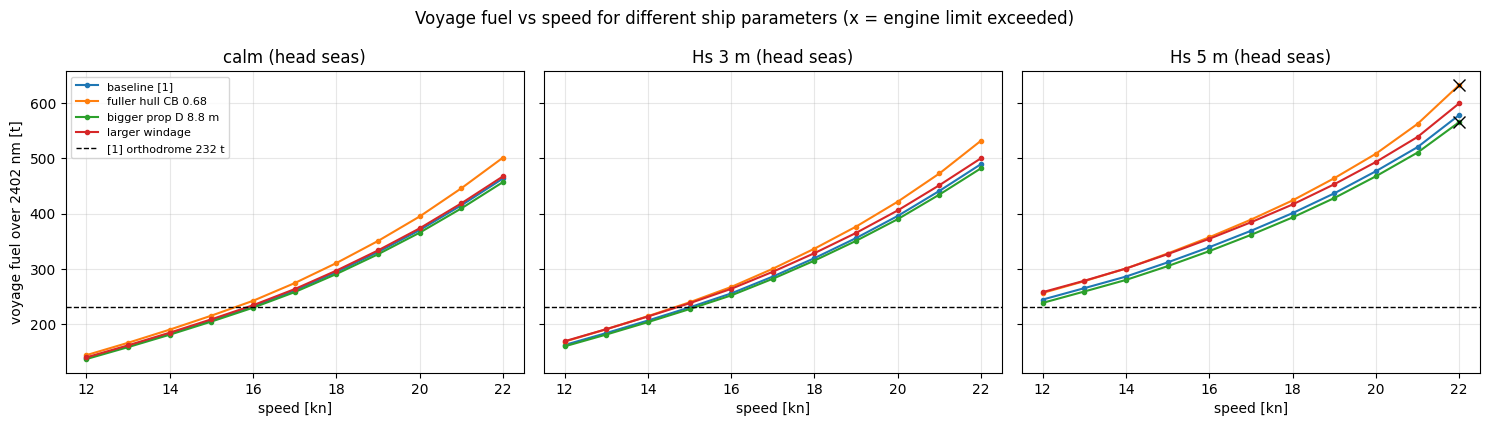

In [6]:
# =============================================================================
# TASK 1.2 - Sensitivity sandbox: ship parameters x speed x sea state
# Standalone: only needs adv_fuel_model.py on disk (TASK 1.2 CELL 1).
# Edit SHIPS / SPEEDS_KN / SEA_STATES below and re-run.
# =============================================================================
import os, sys, importlib
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.getcwd())
import adv_fuel_model as fm
importlib.reload(fm)

# ---- what to compare (edit here) ----------------------------------------------
SHIPS = {
    "baseline [1]":        fm.ShipParticulars(),
    "fuller hull CB 0.68": fm.ShipParticulars(CB=0.68),
    "bigger prop D 8.8 m": fm.ShipParticulars(D_prop=8.8),
    "larger windage":      fm.ShipParticulars(A_F=1200),
}
SPEEDS_KN = np.arange(12, 22.1, 1.0)
SEA_STATES = {"calm": (0.0, 10.0), "Hs 3 m": (3.0, 9.0), "Hs 5 m": (5.0, 11.0)}   # (Hs, T0)
HEADING, WAVE_FROM = 270.0, 270.0          # head seas
DISTANCE_NM = 2402.05                      # [1] Table 2 orthodrome length

# ---- run ----------------------------------------------------------------------
fig, axs = plt.subplots(1, len(SEA_STATES), figsize=(5 * len(SEA_STATES), 4.3), sharey=True)
print(f"{'ship':22s} {'sea':7s} {'kn':>4s} {'PB kW':>8s} {'%MCR':>6s} {'FOC t/h':>8s} {'voyage t':>9s} feasible")
for ax, (sea, (Hs, T0)) in zip(np.atleast_1d(axs), SEA_STATES.items()):
    for name, ship in SHIPS.items():
        res = [fm.leg_performance(v, HEADING, ship, Hs=Hs, T0=T0, wave_from_deg=WAVE_FROM,
                                  wind_speed=2.5 * Hs, wind_from_deg=WAVE_FROM, distance_nm=DISTANCE_NM)
               for v in SPEEDS_KN]
        ax.plot(SPEEDS_KN, [r["fuel_t"] for r in res], "o-", ms=3, label=name)
        bad = [v for v, r in zip(SPEEDS_KN, res) if not r["feasible"]]
        if bad:
            ax.plot(bad, [r["fuel_t"] for v, r in zip(SPEEDS_KN, res) if not r["feasible"]], "kx", ms=8)
        r16 = res[int(np.argmin(np.abs(SPEEDS_KN - 16)))]
        print(f"{name:22s} {sea:7s} {16:4d} {r16['PB_kW']:8.0f} {100 * r16['load_MCR']:6.1f} "
              f"{r16['FOC_t_h']:8.3f} {r16['fuel_t']:9.1f} {r16['feasible']}")
    ax.axhline(232.03, color="k", ls="--", lw=1, label="[1] orthodrome 232 t")
    ax.set(title=f"{sea} (head seas)", xlabel="speed [kn]")
    ax.grid(alpha=0.3)
np.atleast_1d(axs)[0].set_ylabel(f"voyage fuel over {DISTANCE_NM:.0f} nm [t]")
np.atleast_1d(axs)[0].legend(fontsize=8)
plt.suptitle("Voyage fuel vs speed for different ship parameters (x = engine limit exceeded)")
plt.tight_layout()
plt.show()

### Task 1.3

In [7]:
%%writefile adv_motion_model.py
"""
adv_motion_model.py
===================
Ship-motion transfer functions (RAOs) for heave, pitch and roll, used to evaluate the
seakeeping criteria of [1] (significant heave > 3.5 m, significant roll > 5 deg) and the
local accelerations of [1] Fig. 10.

[1] Kytariolou & Themelis (2022), J. Navigation 75(6) - used NEWDRIFT+ (3D panel, not public).

Open substitute implemented here (no executable needed, runs anywhere):
  heave, pitch : closed-form strip-theory approximation of
                 Jensen, J.J., Mansour, A.E., Olsen, A.S. (2004). Estimation of ship motions
                 using closed-form expressions. Ocean Engineering 31, 61-85.
                 (box-like hull of breadth C_B*B, draught T, forward speed, any heading)
  roll         : linear 1-DOF roll model (GM, radius of gyration, linearised damping ratio),
                 Froude-Krylov wave-slope excitation with effective-slope coefficient and
                 length/beam cancellation factors.
External strip-theory / panel results (SEAWAY, PDSTRIP, Capytaine, ...) can be plugged in
instead through TabulatedRAO (CSV table omega x heading x speed).

Every RAO has the signature used by adv_fuel_model.motion_spectrum:
    rao(we_abs, omega, Vs, mu_deg) -> amplitude
  linear motions : x0 / zeta0            [m/m]
  angular motions: x0 / (k zeta0)        [rad/rad]   (k = omega^2/g, wave slope)
Headings: mu = 180 deg head seas, 90 deg beam, 0 deg following ([1] convention).
"""
from dataclasses import dataclass
import numpy as np

G = 9.81
KN = 1852.0 / 3600.0


@dataclass
class MotionParticulars:
    # main dimensions ([1] Table 1)
    L: float = 244.80
    B: float = 32.25
    T: float = 12.60
    CB: float = 0.64                 # estimate (same as adv_fuel_model.ShipParticulars)
    # roll (estimates for a loaded 4250 TEU containership)
    GM: float = 1.2                  # metacentric height [m]
    kxx_B: float = 0.40              # roll radius of gyration incl. added inertia / B
    zeta_roll: float = 0.05          # linearised roll damping ratio (incl. bilge keels)
    r_eff_slope: float = 0.70        # effective wave-slope coefficient (Froude-Krylov reduction)
    # points of interest (x + forward of midship/LCG, z + above waterline) - estimates
    x_bridge: float = -0.20 * 244.80
    z_bridge: float = 35.0
    x_bow: float = 0.48 * 244.80
    z_bow: float = 12.0

    @property
    def roll_natural_period(self):
        return 2 * np.pi * self.kxx_B * self.B / np.sqrt(G * self.GM)


def _k(omega):
    return np.asarray(omega, float) ** 2 / G


# =============================================================================
# Heave and pitch - Jensen, Mansour & Olsen (2004)
# =============================================================================
def jensen_heave_pitch(omega, Vs, mu_deg, mp: MotionParticulars):
    """Return (heave/zeta0 [m/m], pitch/zeta0 [rad/m]) for wave frequency omega [rad/s]."""
    w = np.maximum(np.asarray(omega, float), 1e-4)
    k = _k(w)
    L, T = mp.L, mp.T
    Be = mp.CB * mp.B                                  # equivalent box breadth
    Fn = Vs / np.sqrt(G * L)
    cosb = np.cos(np.radians(mu_deg))
    ke = np.maximum(np.abs(k * cosb), 1e-9)            # effective wave number along the hull
    alpha = 1.0 - Fn * np.sqrt(k * L) * cosb           # = omega_e / omega
    A = 2.0 * np.sin(0.5 * k * Be * alpha ** 2) * np.exp(-k * T * alpha ** 2)
    f = np.sqrt((1 - k * T) ** 2 + (A ** 2 / (k * T * alpha ** 3)) ** 2)
    kappa = np.exp(-ke * T)                            # Smith correction
    x = 0.5 * ke * L
    F = kappa * f * np.sin(x) / x
    Gp = kappa * f * 24.0 / ((ke * L) ** 2 * L) * (np.sin(x) - x * np.cos(x))
    eta = 1.0 / np.sqrt((1 - 2 * k * T * alpha ** 2) ** 2 + (A ** 2 / (k * T * alpha ** 2)) ** 2)
    return np.abs(eta * F), np.abs(eta * Gp)


# =============================================================================
# Roll - linear 1-DOF model
# =============================================================================
def roll_rao_slope(omega, Vs, mu_deg, mp: MotionParticulars):
    """Roll amplitude per wave-slope amplitude, phi0 / (k zeta0) [rad/rad]."""
    w = np.maximum(np.asarray(omega, float), 1e-4)
    k = _k(w)
    mu = np.radians(mu_deg)
    we = np.abs(w - k * Vs * np.cos(mu))               # Eq. (8) of [1]
    w_n = 2 * np.pi / mp.roll_natural_period
    lam = we / w_n
    sin_mu = np.abs(np.sin(mu))
    # cancellation of the wave-slope moment along the length and across the beam
    along = np.abs(np.sinc(k * mp.L * np.abs(np.cos(mu)) / (2 * np.pi)))
    across = np.abs(np.sinc(k * mp.B * sin_mu / (2 * np.pi))) * np.exp(-0.5 * k * mp.T)
    excitation = mp.r_eff_slope * sin_mu * along * across
    return excitation / np.sqrt((1 - lam ** 2) ** 2 + (2 * mp.zeta_roll * lam) ** 2)


# =============================================================================
# RAO callables with the adv_fuel_model.motion_spectrum signature
# =============================================================================
def make_raos(mp: MotionParticulars = None):
    """Return dict of RAO callables rao(we_abs, omega, Vs, mu_deg)."""
    mp = mp or MotionParticulars()
    heave = lambda we, w, V, mu: jensen_heave_pitch(w, V, mu, mp)[0]                 # m/m
    pitch = lambda we, w, V, mu: jensen_heave_pitch(w, V, mu, mp)[1] / np.maximum(_k(w), 1e-9)  # rad/(k zeta0)
    roll = lambda we, w, V, mu: roll_rao_slope(w, V, mu, mp)                          # rad/(k zeta0)
    return {"heave": heave, "pitch": pitch, "roll": roll}


# =============================================================================
# Local accelerations ([1] Fig. 10)
# =============================================================================
def local_acceleration_raos(omega, Vs, mu_deg, x, z, mp: MotionParticulars = None, include_gravity=False):
    """Vertical and lateral acceleration amplitudes per wave amplitude [m/s2 per m] at point (x, z).
    Vertical: heave and pitch combined in quadrature (pitch ~90 deg out of phase with heave in the
    closed-form model). Lateral: roll only (z * phi'' [+ g * phi]); sway/yaw are NOT modelled."""
    mp = mp or MotionParticulars()
    w = np.asarray(omega, float)
    k = _k(w)
    we = np.abs(w - k * Vs * np.cos(np.radians(mu_deg)))
    heave, pitch = jensen_heave_pitch(w, Vs, mu_deg, mp)
    vert_disp = np.sqrt(heave ** 2 + (x * pitch) ** 2)
    roll = roll_rao_slope(w, Vs, mu_deg, mp) * k                       # rad per m of wave amplitude
    lat = roll * (np.abs(z * we ** 2 - G) if include_gravity else np.abs(z) * we ** 2)
    return we ** 2 * vert_disp, lat


def significant_response(omega, S_omega, rao_amp):
    """4 * sqrt(m0) of a response with amplitude RAO 'rao_amp' on the wave-frequency grid
    (Eqs. 14, 17, 18 of [1]; integrating over omega is equivalent to omega_e)."""
    trapz = getattr(np, "trapezoid", None) or np.trapz
    return 4.0 * np.sqrt(trapz(S_omega * np.asarray(rao_amp) ** 2, omega))


# =============================================================================
# Plug-in for external RAO tables (SEAWAY / PDSTRIP / Capytaine export)
# =============================================================================
class TabulatedRAO:
    """RAO from a table with columns: omega [rad/s], mu_deg, speed_kn, amplitude.
    Amplitude convention must match the motion: x0/zeta0 (linear) or x0/(k zeta0) (angular).
    Linear interpolation on the regular (omega, mu, speed) grid; outside -> nearest edge."""

    def __init__(self, csv_path, freq_is_encounter=False):
        import pandas as pd
        from scipy.interpolate import RegularGridInterpolator
        df = pd.read_csv(csv_path)
        self.w = np.sort(df["omega"].unique())
        self.mu = np.sort(df["mu_deg"].unique())
        self.v = np.sort(df["speed_kn"].unique())
        cube = (df.set_index(["omega", "mu_deg", "speed_kn"])["amplitude"]
                  .reindex(pd.MultiIndex.from_product([self.w, self.mu, self.v])).values
                  .reshape(len(self.w), len(self.mu), len(self.v)))
        self._f = RegularGridInterpolator((self.w, self.mu, self.v), cube, bounds_error=False, fill_value=None)
        self.freq_is_encounter = freq_is_encounter

    def __call__(self, we, w, Vs, mu_deg):
        f = np.clip(np.asarray(we if self.freq_is_encounter else w, float), self.w[0], self.w[-1])
        mu = np.clip(np.full_like(f, float(mu_deg) % 360.0 if float(mu_deg) % 360.0 <= 180
                                  else 360.0 - float(mu_deg) % 360.0), self.mu[0], self.mu[-1])
        v = np.clip(np.full_like(f, Vs / KN), self.v[0], self.v[-1])
        return self._f(np.column_stack([f, mu, v]))

Writing adv_motion_model.py


Roll natural period T_phi = 23.6 s (GM = 1.2 m, kxx = 0.4 B)

Cross-check vs [1] Fig. 10 (Hs 4.0 m, 16 kn, mu 150 deg) - peak value [m/s2] @ Tp [s]
   quantity                    [1]     this model
   bow vertical       1.88 @ 11.0   1.98 @ 14.0
   bridge vertical    0.64 @ 12.0   0.98 @ 14.5
   bow lateral        0.29 @ 11.0   0.02 @ 22.0
   bridge lateral     0.18 @ 12.0   0.06 @ 22.0

Significant heave [m] / roll [deg] at 16 kn  (* = exceeds [1] limits 3.5 m / 5.0 deg)
   mu [deg]    Hs4 Tp10        Hs6 Tp12        Hs8 Tp14     
        180    0.23  /  0.0     0.94  /  0.0     2.70  /  0.0  
        150    0.33  /  0.0     1.35  /  0.1     3.65* /  0.3  
        120    1.21  /  0.2     3.88* /  0.5     6.92* /  1.2  
         90    4.68* /  0.9     7.80* /  1.8    10.35* /  3.0  
         60    1.10  /  0.6     2.96  /  1.9     5.23* /  4.5  
         30    0.39  /  0.8     0.92  /  1.7     2.41  /  4.5  
          0    0.31  /  0.0     0.68  /  0.0     1.75  /  0.0  


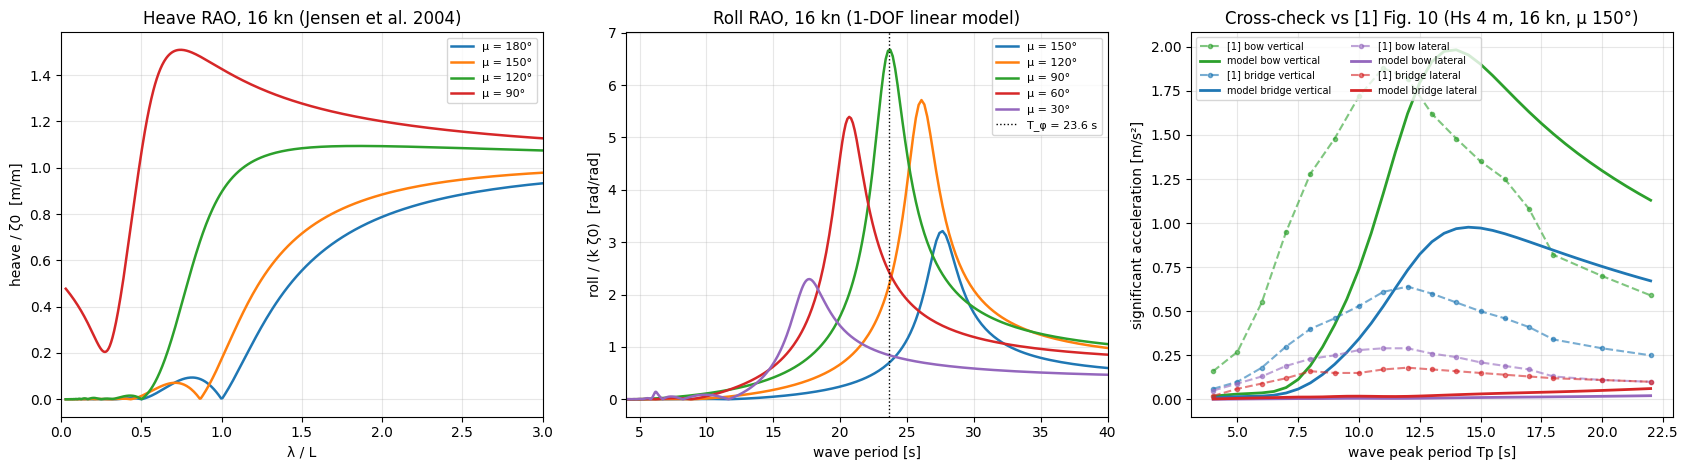

Saved -> outputs/phase1/motion_model_verification.png


In [8]:
# =============================================================================
# TASK 1.3 - CELL 2/2 : Heave / roll response + qualitative cross-check vs [1] Fig. 10
# Standalone: needs adv_motion_model.py (TASK 1.3 CELL 1) and adv_fuel_model.py
# (TASK 1.2 CELL 1) on disk - both persist after kernel restarts.
# =============================================================================
import os, sys, importlib
import numpy as np
import matplotlib.pyplot as plt

for f in ("adv_motion_model.py", "adv_fuel_model.py"):
    if not os.path.exists(f):
        raise FileNotFoundError(f"{f} not found: run the CELL 1 of its task once to write it.")
sys.path.insert(0, os.getcwd())
import adv_motion_model as mm, adv_fuel_model as fm
importlib.reload(mm); importlib.reload(fm)

mp = mm.MotionParticulars()
rao = mm.make_raos(mp)
Vs = 16 * fm.KN                                   # [1] Fig. 10 / Cases A-B speed
w = np.linspace(0.05, 3.0, 1500)                  # wave frequency grid [rad/s]
print(f"Roll natural period T_phi = {mp.roll_natural_period:.1f} s (GM = {mp.GM} m, kxx = {mp.kxx_B} B)")

# ---- [1] Fig. 10, digitised: Hs = 4 m, 16 kn, mu = 150 deg (values = significant, 4 rms) ----
FIG10_TP = np.array([4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 20, 22], float)
FIG10 = {
    "bow vertical":    [0.16, 0.27, 0.55, 0.95, 1.28, 1.48, 1.72, 1.88, 1.82, 1.62, 1.48, 1.35, 1.25, 1.08, 0.82, 0.70, 0.59],
    "bridge vertical": [0.06, 0.10, 0.18, 0.30, 0.40, 0.46, 0.53, 0.61, 0.64, 0.60, 0.55, 0.50, 0.46, 0.41, 0.34, 0.29, 0.25],
    "bow lateral":     [0.05, 0.09, 0.13, 0.19, 0.23, 0.25, 0.28, 0.29, 0.29, 0.26, 0.24, 0.21, 0.19, 0.17, 0.13, 0.11, 0.10],
    "bridge lateral":  [0.02, 0.06, 0.09, 0.12, 0.16, 0.15, 0.15, 0.17, 0.18, 0.17, 0.16, 0.15, 0.14, 0.13, 0.12, 0.11, 0.10],
}
MU_FIG10, HS_FIG10 = 150.0, 4.0
tp_grid = np.arange(4, 22.01, 0.5)
ours = {k: [] for k in FIG10}
for Tp in tp_grid:
    S = fm.jonswap(w, HS_FIG10, Tp)
    bv, bl = mm.local_acceleration_raos(w, Vs, MU_FIG10, mp.x_bow, mp.z_bow, mp)
    rv, rl = mm.local_acceleration_raos(w, Vs, MU_FIG10, mp.x_bridge, mp.z_bridge, mp)
    for key, r in zip(["bow vertical", "bridge vertical", "bow lateral", "bridge lateral"], [bv, rv, bl, rl]):
        ours[key].append(mm.significant_response(w, S, r))

print(f"\nCross-check vs [1] Fig. 10 (Hs {HS_FIG10} m, 16 kn, mu {MU_FIG10:.0f} deg) - peak value [m/s2] @ Tp [s]")
print(f"   {'quantity':16s} {'[1]':>14s} {'this model':>14s}")
for key in FIG10:
    i1, i2 = int(np.argmax(FIG10[key])), int(np.argmax(ours[key]))
    print(f"   {key:16s} {FIG10[key][i1]:6.2f} @ {FIG10_TP[i1]:4.1f} {ours[key][i2]:6.2f} @ {tp_grid[i2]:4.1f}")

# ---- significant heave / roll vs heading: check against [1] criteria -------------------
HEAVE_LIM, ROLL_LIM = 3.5, 5.0
headings = [180, 150, 120, 90, 60, 30, 0]
seas = [(4, 10), (6, 12), (8, 14)]
print(f"\nSignificant heave [m] / roll [deg] at 16 kn  (* = exceeds [1] limits {HEAVE_LIM} m / {ROLL_LIM} deg)")
print("   mu [deg] " + "".join(f"   Hs{h} Tp{t:<2d}     " for h, t in seas))
for mu in headings:
    row = ""
    for Hs, Tp in seas:
        S = fm.jonswap(w, Hs, Tp)
        h = fm.motion_statistics(w, fm.motion_spectrum(w, S, rao["heave"], Vs, mu, "linear"))["significant"]
        r = np.degrees(fm.motion_statistics(w, fm.motion_spectrum(w, S, rao["roll"], Vs, mu, "angular"))["significant"])
        row += f"  {h:5.2f}{'*' if h > HEAVE_LIM else ' '} / {r:4.1f}{'*' if r > ROLL_LIM else ' '} "
    print(f"   {mu:8d} {row}")

# ---- figures ---------------------------------------------------------------------------
fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
lam_L = 2 * np.pi * fm.G / w ** 2 / mp.L
ax = axs[0]
for mu in [180, 150, 120, 90]:
    ax.plot(lam_L, rao["heave"](None, w, Vs, mu), lw=1.8, label=f"μ = {mu}°")
ax.set(xlim=(0, 3), xlabel="λ / L", ylabel="heave / ζ0  [m/m]", title="Heave RAO, 16 kn (Jensen et al. 2004)")
ax.grid(alpha=0.3); ax.legend(fontsize=8)

ax = axs[1]
T_w = 2 * np.pi / w
for mu in [150, 120, 90, 60, 30]:
    ax.plot(T_w, rao["roll"](None, w, Vs, mu), lw=1.8, label=f"μ = {mu}°")
ax.axvline(mp.roll_natural_period, color="k", ls=":", lw=1, label=f"T_φ = {mp.roll_natural_period:.1f} s")
ax.set(xlim=(4, 40), xlabel="wave period [s]", ylabel="roll / (k ζ0)  [rad/rad]",
       title="Roll RAO, 16 kn (1-DOF linear model)")
ax.grid(alpha=0.3); ax.legend(fontsize=8)

ax = axs[2]
colors = {"bow vertical": "tab:green", "bridge vertical": "tab:blue", "bow lateral": "tab:purple",
          "bridge lateral": "tab:red"}
for key, c in colors.items():
    ax.plot(FIG10_TP, FIG10[key], "o--", ms=3, color=c, alpha=0.6, label=f"[1] {key}")
    ax.plot(tp_grid, ours[key], "-", lw=2, color=c, label=f"model {key}")
ax.set(xlabel="wave peak period Tp [s]", ylabel="significant acceleration [m/s²]",
       title="Cross-check vs [1] Fig. 10 (Hs 4 m, 16 kn, μ 150°)")
ax.grid(alpha=0.3); ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
os.makedirs("outputs/phase1", exist_ok=True)
plt.savefig("outputs/phase1/motion_model_verification.png", dpi=150)
plt.show()
print("Saved -> outputs/phase1/motion_model_verification.png")

### Task 1.4

In [9]:
%%writefile adv_hazard_flag.py
"""
adv_hazard_flag.py
==================
"Hazardous event" flag for a ship transit point (Phase 1 of the ADV-Atlas pipeline).

An event is HAZARDOUS if at least one of the two criteria is met:

  (A) significant-value criterion ([1] Sec. 4.6, Case B)
        significant heave > 3.5 m   OR   significant roll > 5 deg
      computed with the spectral method of [1] Eqs. (7), (14)-(18) (adv_fuel_model)
      and the RAOs of adv_motion_model, for the actual Hs, Tp, wave direction,
      ship heading and speed.

  (B) individual-wave abnormality-index criterion (Haver 2004, Draupner)
        AI = H_max / H_s > 2      AND   H_max >= H_MAX_MIN_M
      for single extreme waves too short-lived to show up in (A).
      H_max source, in order of preference:
        1. observed  (buoy / SAR OSW H_max)       -> AI is a measurement
        2. ERA5 'hmax' (expected max over 3 h, includes non-linear kurtosis effects)
        3. linear-sea expectation from Hs, Tp and exposure time (proxy only), using the
           Naess (1985) wave-height distribution (Rayleigh corrected for spectral bandwidth,
           P(H > a Hs) = exp(-c a^2), c = 4/(1-r), r = min. autocorrelation; Rayleigh: c = 2)
      With source 3 AI depends only on the number of waves and the spectrum shape, so it is
      reported together with P_rogue = probability of at least one wave > 2 Hs in the exposure.
      AI from a model / altimeter Hs is a statistical expectation, not a point prediction
      (ADV proposal, Sec. 8).

Thresholds and conventions are module constants and can be overridden per call.
"""
import os, sys
from functools import lru_cache
import numpy as np

sys.path.insert(0, os.getcwd())
import adv_fuel_model as fm          # Eqs. (7), (14)-(18), JONSWAP     (TASK 1.2)
import adv_motion_model as mm        # heave / roll RAOs                 (TASK 1.3)

HEAVE_SIG_LIM_M = 3.5                # [1] Case B
ROLL_SIG_LIM_DEG = 5.0               # [1] Case B
AI_LIM = 2.0                         # Haver (2004)
H_MAX_MIN_M = 8.0                    # abnormal wave must also be large in absolute terms (project choice)
EXPOSURE_H = 3.0                     # exposure window = CMEMS time step [h]
EULER_GAMMA = 0.5772156649

_W = np.linspace(0.05, 3.0, 1200)    # wave-frequency grid [rad/s]
_MP = mm.MotionParticulars()
_RAO = mm.make_raos(_MP)


# =============================================================================
# (A) significant-value criterion
# =============================================================================
@lru_cache(maxsize=200_000)
def _response_unit_hs(tp_r, mu_r, v_r):
    """Significant heave [m] and roll [deg] for Hs = 1 m (linear -> scales with Hs).
    Cached on rounded (Tp, mu, V) to make long time series cheap."""
    Vs = v_r * fm.KN
    S = fm.jonswap(_W, 1.0, tp_r)
    h = fm.motion_statistics(_W, fm.motion_spectrum(_W, S, _RAO["heave"], Vs, mu_r, "linear"))["significant"]
    r = fm.motion_statistics(_W, fm.motion_spectrum(_W, S, _RAO["roll"], Vs, mu_r, "angular"))["significant"]
    return float(h), float(np.degrees(r))


def significant_motions(hs, tp, mu_deg, speed_kn):
    """Significant heave [m] and roll [deg] (Eqs. 14-18 of [1])."""
    tp_r = round(max(float(tp), 2.0) * 4) / 4                  # 0.25 s bins
    mu_r = round((float(mu_deg) % 360.0) / 5) * 5 % 360        # 5 deg bins
    v_r = round(float(speed_kn) * 2) / 2                       # 0.5 kn bins
    h1, r1 = _response_unit_hs(tp_r, mu_r, v_r)
    return h1 * hs, r1 * hs


# =============================================================================
# (B) abnormality-index criterion
# =============================================================================
def zero_crossing_period(tp, gamma=3.3):
    """Tz = 2 pi sqrt(m0/m2) of the JONSWAP spectrum of [1] Eq. (7)."""
    trapz = getattr(np, "trapezoid", None) or np.trapz
    S = fm.jonswap(_W, 1.0, tp, gamma)
    return 2 * np.pi * np.sqrt(trapz(S, _W) / trapz(_W ** 2 * S, _W))


def n_waves(tp, exposure_h=EXPOSURE_H, tz=None):
    tz = zero_crossing_period(tp) if tz is None else tz
    return max(exposure_h * 3600.0 / tz, 1.0)


@lru_cache(maxsize=2000)
def naess_coefficient(tp_r, gamma=3.3):
    """c = 4 / (1 - r), r = minimum of the normalised autocorrelation of the JONSWAP spectrum
    (Naess 1985). c = 2 gives the Rayleigh distribution (infinitely narrow spectrum)."""
    trapz = getattr(np, "trapezoid", None) or np.trapz
    S = fm.jonswap(_W, 1.0, tp_r, gamma)
    m0 = trapz(S, _W)
    tau = np.linspace(0.05, 1.2 * tp_r, 400)
    rho = np.array([trapz(S * np.cos(_W * t), _W) for t in tau]) / m0
    return 4.0 / (1.0 - rho.min())


def expected_ai(N, c=2.0):
    """E[H_max]/H_s for N waves with P(H > a Hs) = exp(-c a^2) (Gumbel approximation)."""
    lnN = np.log(N)
    return np.sqrt(lnN / c) + EULER_GAMMA / (2.0 * np.sqrt(c * lnN))


def p_rogue(N, ai=AI_LIM, c=2.0):
    """P(at least one wave with H > ai * Hs among N waves)."""
    return 1.0 - np.exp(-N * np.exp(-c * ai ** 2))


def rayleigh_expected_ai(N):
    return expected_ai(N, 2.0)


def rayleigh_p_rogue(N, ai=AI_LIM):
    return p_rogue(N, ai, 2.0)


def abnormality(hs, tp, hmax_obs=None, hmax_era5=None, exposure_h=EXPOSURE_H, tz=None,
                distribution="naess"):
    """Return dict(AI, H_max, source, P_rogue). distribution: 'naess' (default) or 'rayleigh'."""
    N = n_waves(tp, exposure_h, tz)
    c = naess_coefficient(round(max(float(tp), 2.0) * 4) / 4) if distribution == "naess" else 2.0
    p = float(p_rogue(N, AI_LIM, c))
    if hmax_obs is not None and np.isfinite(hmax_obs):
        hmax, src = float(hmax_obs), "observed"
    elif hmax_era5 is not None and np.isfinite(hmax_era5):
        hmax, src = float(hmax_era5), "era5_hmax"
    else:
        hmax, src = float(expected_ai(N, c) * hs), f"linear_{distribution}"
    return {"AI": hmax / hs if hs > 0 else np.nan, "H_max_m": hmax, "AI_source": src,
            "P_rogue": p, "N_waves": N}


# =============================================================================
# Combined flag
# =============================================================================
def hazard_flag(hs, tp, wave_from_deg, heading_deg, speed_kn,
                hmax_obs=None, hmax_era5=None, tz=None, exposure_h=EXPOSURE_H,
                heave_lim=HEAVE_SIG_LIM_M, roll_lim=ROLL_SIG_LIM_DEG,
                ai_lim=AI_LIM, hmax_min=H_MAX_MIN_M):
    """Hazard flag for ONE transit point. Directions: wave 'coming from', ship heading (deg, nautical)."""
    mu = float(fm.wave_relative_heading(heading_deg, wave_from_deg))
    heave, roll = significant_motions(hs, tp, mu, speed_kn)
    ab = abnormality(hs, tp, hmax_obs, hmax_era5, exposure_h, tz)
    f_heave, f_roll = heave > heave_lim, roll > roll_lim
    f_sig = f_heave or f_roll
    f_ai = (ab["AI"] > ai_lim) and (ab["H_max_m"] >= hmax_min)
    kind = "both" if (f_sig and f_ai) else ("significant" if f_sig else ("abnormal" if f_ai else "none"))
    return {"mu_deg": mu, "heave_sig_m": heave, "roll_sig_deg": roll,
            "flag_heave": f_heave, "flag_roll": f_roll, "flag_significant": f_sig,
            **ab, "flag_abnormal": f_ai, "hazard": f_sig or f_ai, "hazard_type": kind}


def hazard_flag_dataframe(df, hs="hs", tp="tp", wave_from="wave_dir", heading="heading",
                          speed="speed_kn", hmax_obs=None, hmax_era5=None, tz=None, **kw):
    """Apply hazard_flag to every row of a pandas DataFrame (Phase 2 time series).
    Column names are arguments; optional columns may be None. Returns a new DataFrame."""
    import pandas as pd
    get = lambda r, c: (r[c] if (c is not None and c in r and pd.notna(r[c])) else None)
    rows = [hazard_flag(r[hs], r[tp], r[wave_from], r[heading], r[speed],
                        hmax_obs=get(r, hmax_obs), hmax_era5=get(r, hmax_era5), tz=get(r, tz), **kw)
            for _, r in df.iterrows()]
    return pd.concat([df.reset_index(drop=True), pd.DataFrame(rows)], axis=1)

Writing adv_hazard_flag.py


1) Abnormality index, linear sea Hs=4.0 m Tp=10.0 s, 3 h  (N ≈ 1360 waves, Tz = 7.94 s)
   E[Hmax/Hs]     Rayleigh 1.975 | Naess (c=2.31) 1.839 | Monte Carlo 1.841
   P(Hmax/Hs > 2) Rayleigh 0.366 | Naess 0.125 | Monte Carlo 0.143
   -> in a LINEAR sea AI depends only on N and spectrum shape: with model Hs alone it is a likelihood proxy.

2) Draupner anchor: AI = 2.15 (observed) -> flag_abnormal = True, hazard_type = both

3) Example transit points
               time  hs  tp  mu_deg  heave_sig_m  roll_sig_deg   AI AI_source  P_rogue hazard_type
2020-01-15 00:00:00 2.5   8   170.0         0.04          0.00 1.88 era5_hmax     0.15        none
2020-01-15 03:00:00 4.5  10   200.0         0.30          0.03 1.91 era5_hmax     0.12        none
2020-01-15 06:00:00 6.5  12   100.0         7.45          1.43 1.91 era5_hmax     0.11 significant
2020-01-15 09:00:00 5.0  11   150.0         0.71          0.06 2.12 era5_hmax     0.11    abnormal
2020-01-15 12:00:00 9.0  14   170.0         3.15    

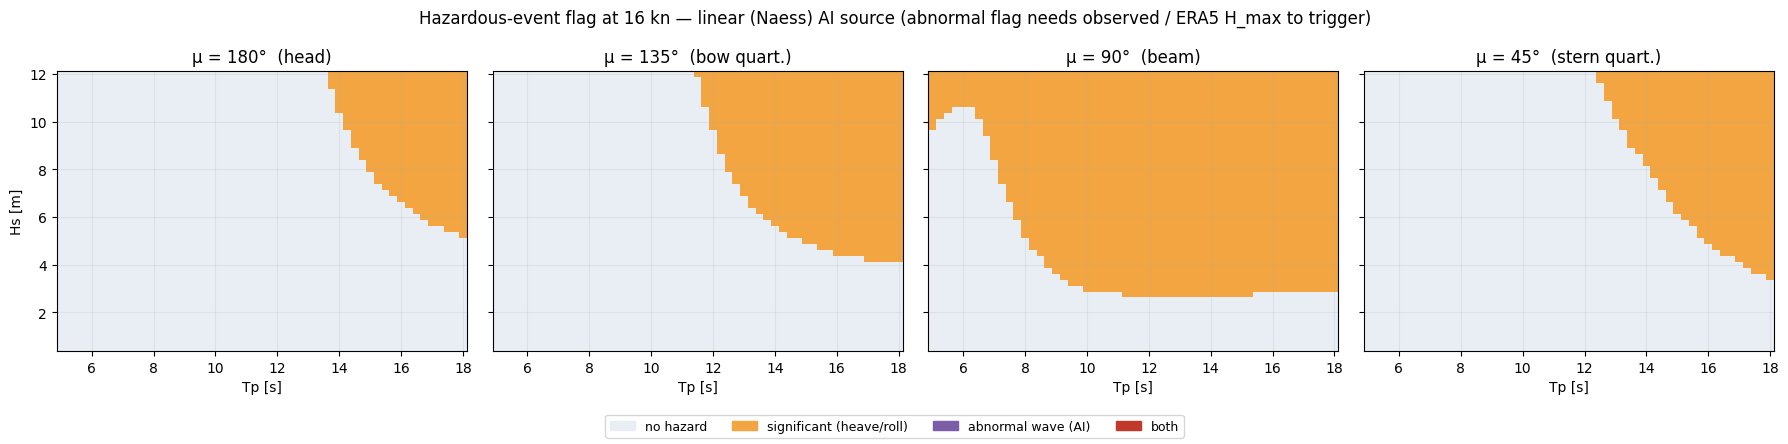

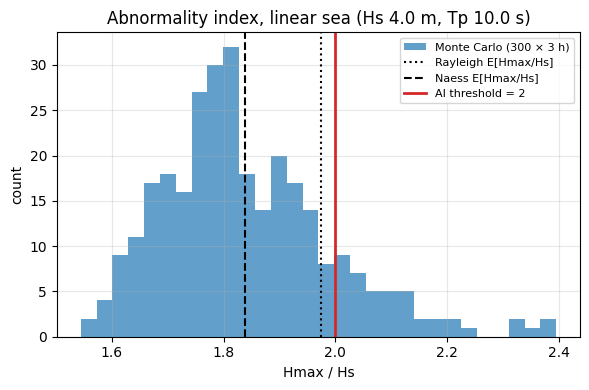

Saved -> outputs/phase1/hazard_flag_maps.png, abnormality_index_mc.png


In [10]:
# =============================================================================
# TASK 1.4 - CELL 2/2 : Verification and maps of the hazardous-event flag
# Standalone: needs adv_hazard_flag.py (CELL 1), adv_motion_model.py (TASK 1.3)
# and adv_fuel_model.py (TASK 1.2) on disk.
# =============================================================================
import os, sys, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

for f in ("adv_hazard_flag.py", "adv_motion_model.py", "adv_fuel_model.py"):
    if not os.path.exists(f):
        raise FileNotFoundError(f"{f} not found: run the CELL 1 of its task once to write it.")
sys.path.insert(0, os.getcwd())
import adv_fuel_model as fm, adv_motion_model as mm, adv_hazard_flag as hz
for m in (fm, mm, hz):
    importlib.reload(m)

SPEED_KN = 16.0

# ---- 1. Abnormality index: Rayleigh / Naess theory vs Monte Carlo of a linear Gaussian sea --
HS, TP, HOURS, N_REAL, DT = 4.0, 10.0, hz.EXPOSURE_H, 300, 0.5
rng = np.random.default_rng(1)
n = int(HOURS * 3600 / DT)
w_fft = 2 * np.pi * np.fft.rfftfreq(n, DT)
S = fm.jonswap(np.maximum(w_fft, 1e-6), HS, TP)
S[0] = 0.0
dw = w_fft[1] - w_fft[0]
amp = np.sqrt(2 * S * dw)
ai_mc = []
for _ in range(N_REAL):
    phases = rng.uniform(0, 2 * np.pi, len(w_fft))
    eta = np.fft.irfft(amp * np.exp(1j * phases) * n / 2, n)        # surface elevation time series
    hs_sample = 4 * eta.std()
    zc = np.where((eta[:-1] > 0) & (eta[1:] <= 0))[0]               # zero down-crossings
    heights = [eta[a:b].max() - eta[a:b].min() for a, b in zip(zc[:-1], zc[1:])]
    ai_mc.append(max(heights) / hs_sample)
ai_mc = np.array(ai_mc)
N = hz.n_waves(TP, HOURS)
print(f"1) Abnormality index, linear sea Hs={HS} m Tp={TP} s, {HOURS:g} h  (N ≈ {N:.0f} waves, "
      f"Tz = {hz.zero_crossing_period(TP):.2f} s)")
c_n = hz.naess_coefficient(TP)
print(f"   E[Hmax/Hs]     Rayleigh {hz.expected_ai(N, 2.0):.3f} | Naess (c={c_n:.2f}) {hz.expected_ai(N, c_n):.3f} "
      f"| Monte Carlo {ai_mc.mean():.3f}")
print(f"   P(Hmax/Hs > 2) Rayleigh {hz.p_rogue(N, 2.0, 2.0):.3f} | Naess {hz.p_rogue(N, 2.0, c_n):.3f} "
      f"| Monte Carlo {np.mean(ai_mc > 2):.3f}")
print("   -> in a LINEAR sea AI depends only on N and spectrum shape: with model Hs alone it is a likelihood proxy.")

# ---- 2. Anchor case: Draupner, 1 Jan 1995 (Haver 2004): Hs = 11.92 m, Hmax = 25.6 m --------
d = hz.hazard_flag(11.92, 15.0, wave_from_deg=0, heading_deg=0, speed_kn=SPEED_KN, hmax_obs=25.6)
print(f"\n2) Draupner anchor: AI = {d['AI']:.2f} ({d['AI_source']}) -> flag_abnormal = {d['flag_abnormal']}, "
      f"hazard_type = {d['hazard_type']}")

# ---- 3. Example transit points (Phase 2 will provide the real time series) --------------
demo = pd.DataFrame({
    "time": pd.to_datetime(["2020-01-15 00:00", "2020-01-15 03:00", "2020-01-15 06:00",
                            "2020-01-15 09:00", "2020-01-15 12:00"]),
    "hs": [2.5, 4.5, 6.5, 5.0, 9.0], "tp": [8, 10, 12, 11, 14],
    "wave_dir": [270, 300, 200, 250, 270], "heading": [280, 280, 280, 280, 280],
    "speed_kn": [16] * 5,
    "hmax_era5": [4.7, 8.6, 12.4, 10.6, 17.1],          # e.g. ERA5 'hmax'
})
out = hz.hazard_flag_dataframe(demo, hmax_era5="hmax_era5")
cols = ["time", "hs", "tp", "mu_deg", "heave_sig_m", "roll_sig_deg", "AI", "AI_source", "P_rogue", "hazard_type"]
print("\n3) Example transit points")
print(out[cols].round({c: 2 for c in cols if c not in ("time", "AI_source", "hazard_type")}).to_string(index=False))

# ---- 4. Hazard maps in (Hs, Tp) for several relative headings ----------------------------
hs_g = np.arange(0.5, 12.01, 0.25)
tp_g = np.arange(5.0, 18.01, 0.25)
codes = {"none": 0, "significant": 1, "abnormal": 2, "both": 3}
cmap = ListedColormap(["#e8eef4", "#f2a541", "#7b5ea7", "#c0392b"])
mus = [180, 135, 90, 45]
fig, axs = plt.subplots(1, len(mus), figsize=(18, 4.4), sharey=True)
for ax, mu in zip(axs, mus):
    Z = np.zeros((len(hs_g), len(tp_g)))
    for i, h in enumerate(hs_g):
        for j, t in enumerate(tp_g):
            r = hz.hazard_flag(h, t, wave_from_deg=(mu + 180) % 360, heading_deg=0, speed_kn=SPEED_KN)
            Z[i, j] = codes[r["hazard_type"]]
    ax.pcolormesh(tp_g, hs_g, Z, cmap=cmap, vmin=-0.5, vmax=3.5, shading="nearest")
    ax.set(title=f"μ = {mu}°  ({'head' if mu == 180 else 'beam' if mu == 90 else 'bow quart.' if mu == 135 else 'stern quart.'})",
           xlabel="Tp [s]")
    ax.grid(alpha=0.2)
axs[0].set_ylabel("Hs [m]")
handles = [plt.Rectangle((0, 0), 1, 1, color=cmap(i)) for i in range(4)]
fig.legend(handles, ["no hazard", "significant (heave/roll)", "abnormal wave (AI)", "both"],
           loc="lower center", ncol=4, fontsize=9)
fig.suptitle(f"Hazardous-event flag at {SPEED_KN:g} kn — linear (Naess) AI source "
             f"(abnormal flag needs observed / ERA5 H_max to trigger)")
plt.tight_layout(rect=(0, 0.07, 1, 1))
os.makedirs("outputs/phase1", exist_ok=True)
plt.savefig("outputs/phase1/hazard_flag_maps.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(ai_mc, bins=30, alpha=0.7, label=f"Monte Carlo ({N_REAL} × {HOURS:g} h)")
ax.axvline(hz.expected_ai(N, 2.0), color="k", ls=":", label="Rayleigh E[Hmax/Hs]")
ax.axvline(hz.expected_ai(N, c_n), color="k", ls="--", label="Naess E[Hmax/Hs]")
ax.axvline(hz.AI_LIM, color="tab:red", lw=2, label="AI threshold = 2")
ax.set(xlabel="Hmax / Hs", ylabel="count", title=f"Abnormality index, linear sea (Hs {HS} m, Tp {TP} s)")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/phase1/abnormality_index_mc.png", dpi=150)
plt.show()
print("Saved -> outputs/phase1/hazard_flag_maps.png, abnormality_index_mc.png")